# Simulación de pensiones con Monte Carlo

<div class="aperture-pasos">

## Monte Carlo aplicado a pensiones

1. **Generar rendimientos R**<br>
2. **Actualizar el saldo**<br>
3. **Recorrer la vida laboral**<br>
4. **Simular N trayectorias**<br>
5. **Leer el saldo final**<br>
6. **Probabilidad de la meta**<br>
</div>

### Datos: ahorro para la pensión invertido en VOO

Una persona empieza a trabajar a los 23 años y ahorra para su pensión hasta los 55 (32 años), invirtiendo todo en VOO, un fondo que replica el S&P 500. Aporta USD 500 al mes al inicio y el aporte crece hasta USD 1,500 al final de su vida laboral. La rentabilidad real del S&P 500 es μ = 8.6% anual con volatilidad σ = 20%. Todo está en dólares de hoy (términos reales). La pregunta es: **¿qué probabilidad hay de llegar a USD 1 millón?**

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

# Parámetros del análisis (en dólares de hoy)
EDAD_INICIO, EDAD_RETIRO = 23, 55
HORIZONTE = EDAD_RETIRO - EDAD_INICIO  # 32 años
APORTE_INICIAL, APORTE_FINAL = 500, 1_500  # US$ al mes
MU, SIGMA = 0.086, 0.20  # rentabilidad real anual del S&P 500 y su volatilidad
META = 1_000_000  # US$
N_SIM = 100_000
SEMILLA = 42

# El aporte mensual crece en línea recta de 500 a 1,500; se aporta 12 veces al año
aportes = 12 * np.linspace(APORTE_INICIAL, APORTE_FINAL, HORIZONTE)
edades = EDAD_INICIO + 1 + np.arange(HORIZONTE)  # edad al final de cada año
aportado = np.cumsum(aportes)  # total aportado acumulado

pd.Series(
    {
        "horizonte": f"{HORIZONTE} años (de {EDAD_INICIO} a {EDAD_RETIRO})",
        "aporte mensual": f"USD {APORTE_INICIAL:,} → USD {APORTE_FINAL:,}",
        "rentabilidad real μ": f"{MU:.1%}",
        "volatilidad σ": f"{SIGMA:.0%}",
        "meta": f"USD {META:,}",
        "total aportado en la vida laboral": f"USD {aportado[-1]:,.0f}",
        "trayectorias N": f"{N_SIM:,}",
    },
    name="valor",
).to_frame()

,valor
horizonte,32 años (de 23 a 55)
aporte mensual,"USD 500 → USD 1,500"
rentabilidad real μ,8.6%
volatilidad σ,20%
meta,"USD 1,000,000"
total aportado en la vida laboral,"USD 384,000"
trayectorias N,"100,000"


In [2]:
# Gráficas con la estética de la charla: el código está en graficas.py
import graficas

graficas.aplicar_estilo()

> **Qué se hizo.** Se definieron los parámetros del ahorro y el calendario de aportes.
>
> **Cómo.** Los parámetros vienen del planteamiento: 32 años de aportes (de los 23 a los 55), μ = 8.6% y σ = 20% reales del S&P 500, y una meta de USD 1 millón. El aporte mensual crece en línea recta de USD 500 a USD 1,500 con `np.linspace`, y se multiplica por 12 para tener el aporte de cada año.
>
> **Resultado.** El aporte anual va de USD 6,000 a USD 18,000; en toda la vida laboral se aportan USD 384,000.

## Generar rendimientos R

Un rendimiento aleatorio por año, `R ~ N(μ, σ)`.

In [3]:
rng = np.random.default_rng(SEMILLA)

# Un rendimiento real por año para cada trayectoria: matriz N_SIM x HORIZONTE
R = rng.normal(MU, SIGMA, size=(N_SIM, HORIZONTE))

pd.DataFrame(
    {
        "simulado": [R.mean(), R.std(), (R < 0).mean(), R.min(), R.max()],
        "teórico": [MU, SIGMA, stats.norm.cdf(0, MU, SIGMA), None, None],
    },
    index=["media", "desv. estándar", "P(R < 0)", "mínimo", "máximo"],
).round(4)

,simulado,teórico
media,0.0862,0.0860
desv. estándar,0.2000,0.2000
P(R < 0),0.3333,0.3336
mínimo,-0.9311,NaN
máximo,1.1484,NaN


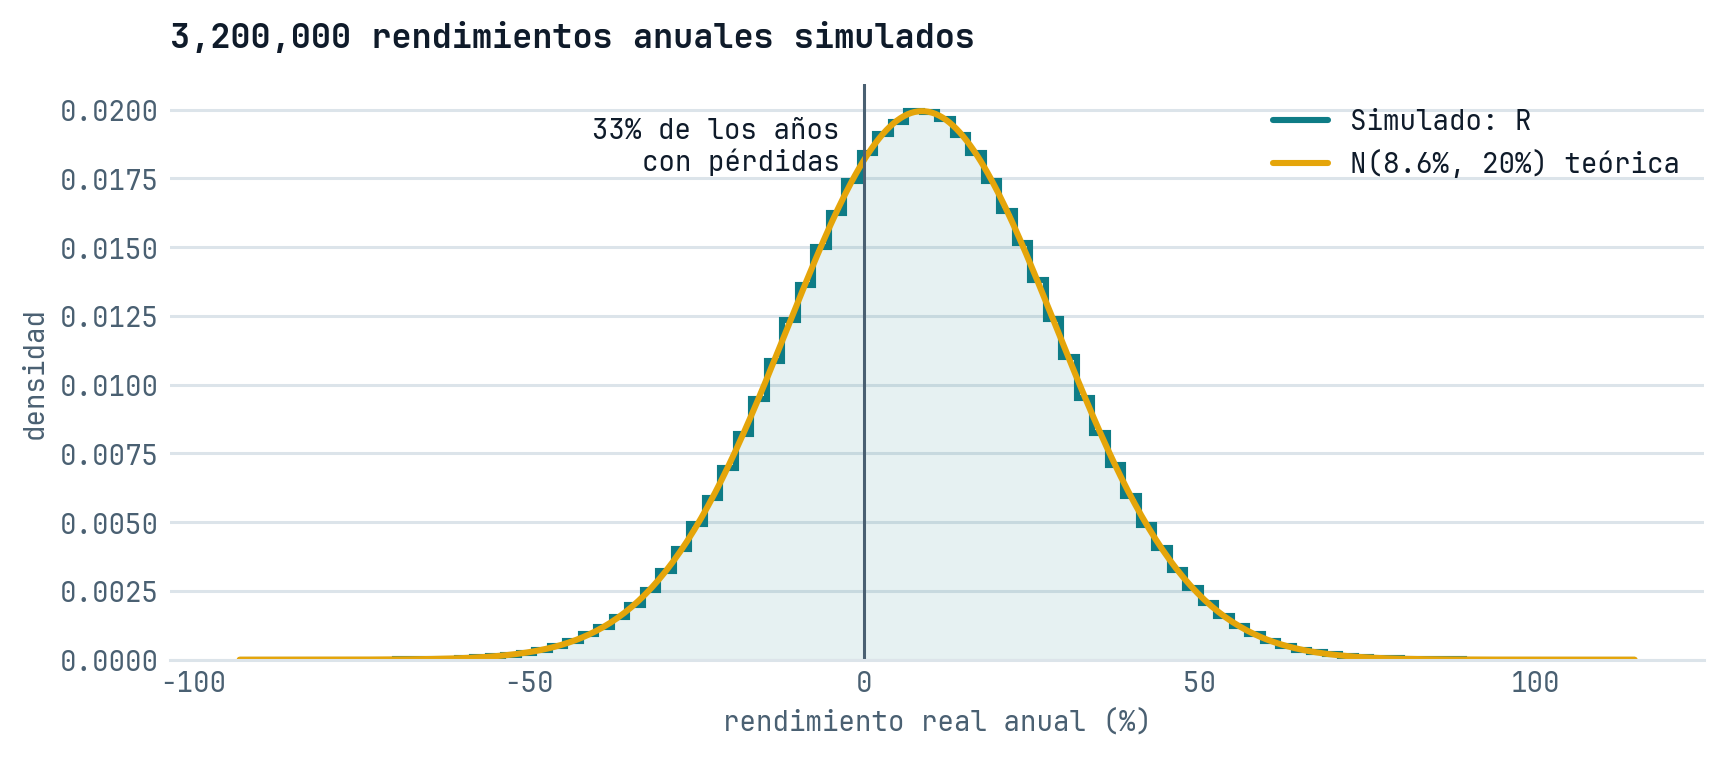

In [4]:
graficas.rendimientos(R, MU, SIGMA)

> **Qué se hizo.** Se generó un rendimiento real aleatorio para cada año de cada trayectoria.
>
> **Cómo.** `rng.normal(MU, SIGMA, size=(N_SIM, HORIZONTE))` crea una matriz de 100,000 × 32 = 3.2 millones de rendimientos, con semilla fija para que el resultado sea reproducible.
>
> **Resultado.** Media de 8.62% y desviación de 20.00%, frente a 8.6% y 20% teóricos. En el 33% de los años el rendimiento es negativo, igual que la probabilidad teórica P(R < 0) = 33.4%. El peor año simulado pierde 93% y el mejor gana 115%.

## Actualizar el saldo

`Saldo = Saldo · (1 + R) + Aporte`

In [5]:
def actualizar(saldo, r, aporte):
    """Un año: el saldo rinde r y al final del año se suma el aporte."""
    return saldo * (1 + r) + aporte


# Primeros 3 años de la primera trayectoria, paso a paso
saldo = 0.0
filas = []
for t in range(3):
    nuevo = actualizar(saldo, R[0, t], aportes[t])
    filas.append([edades[t], saldo, R[0, t], saldo * R[0, t], aportes[t], nuevo])
    saldo = nuevo

pd.DataFrame(
    filas, columns=["edad", "saldo inicial", "rendimiento R", "ganancia", "aporte", "saldo final"]
).round({"saldo inicial": 0, "rendimiento R": 4, "ganancia": 0, "aporte": 0, "saldo final": 0})

,edad,saldo inicial,rendimiento R,ganancia,aporte,saldo final
0,24,0.0,0.1469,0.0,6000.0,6000.0
1,25,6000.0,-0.1220,-732.0,6387.0,11655.0
2,26,11655.0,0.2361,2752.0,6774.0,21181.0


> **Qué se hizo.** Se definió la regla que lleva el saldo de un año al siguiente.
>
> **Cómo.** `Saldo = Saldo · (1 + R) + Aporte`: primero el saldo acumulado rinde R durante el año y al final se suma el aporte. La función `actualizar` aplica esa regla y la tabla la muestra para los primeros 3 años de la primera trayectoria.
>
> **Resultado.** En el primer año no hay saldo que rinda, así que el saldo es solo el aporte (USD 6,000). A los 25 el mercado cae 12.2% y se pierden USD 732, pero el aporte de USD 6,387 compensa; a los 26 sube 23.6% y el saldo llega a USD 21,181.

## Recorrer la vida laboral

Repetir el paso 02 durante 32 años.

In [6]:
# Una vida laboral completa: aplicar el paso 02 cada año, de los 23 a los 55
saldo = 0.0
vida = np.empty(HORIZONTE)
for t in range(HORIZONTE):
    saldo = actualizar(saldo, R[0, t], aportes[t])
    vida[t] = saldo

print(f"Saldo a los {EDAD_RETIRO} años en la primera trayectoria: US$ {vida[-1]:,.0f}")
print(f"Total aportado: US$ {aportado[-1]:,.0f}  |  ganancia del mercado: US$ {vida[-1] - aportado[-1]:,.0f}")

Saldo a los 55 años en la primera trayectoria: US$ 2,206,013
Total aportado: US$ 384,000  |  ganancia del mercado: US$ 1,822,013


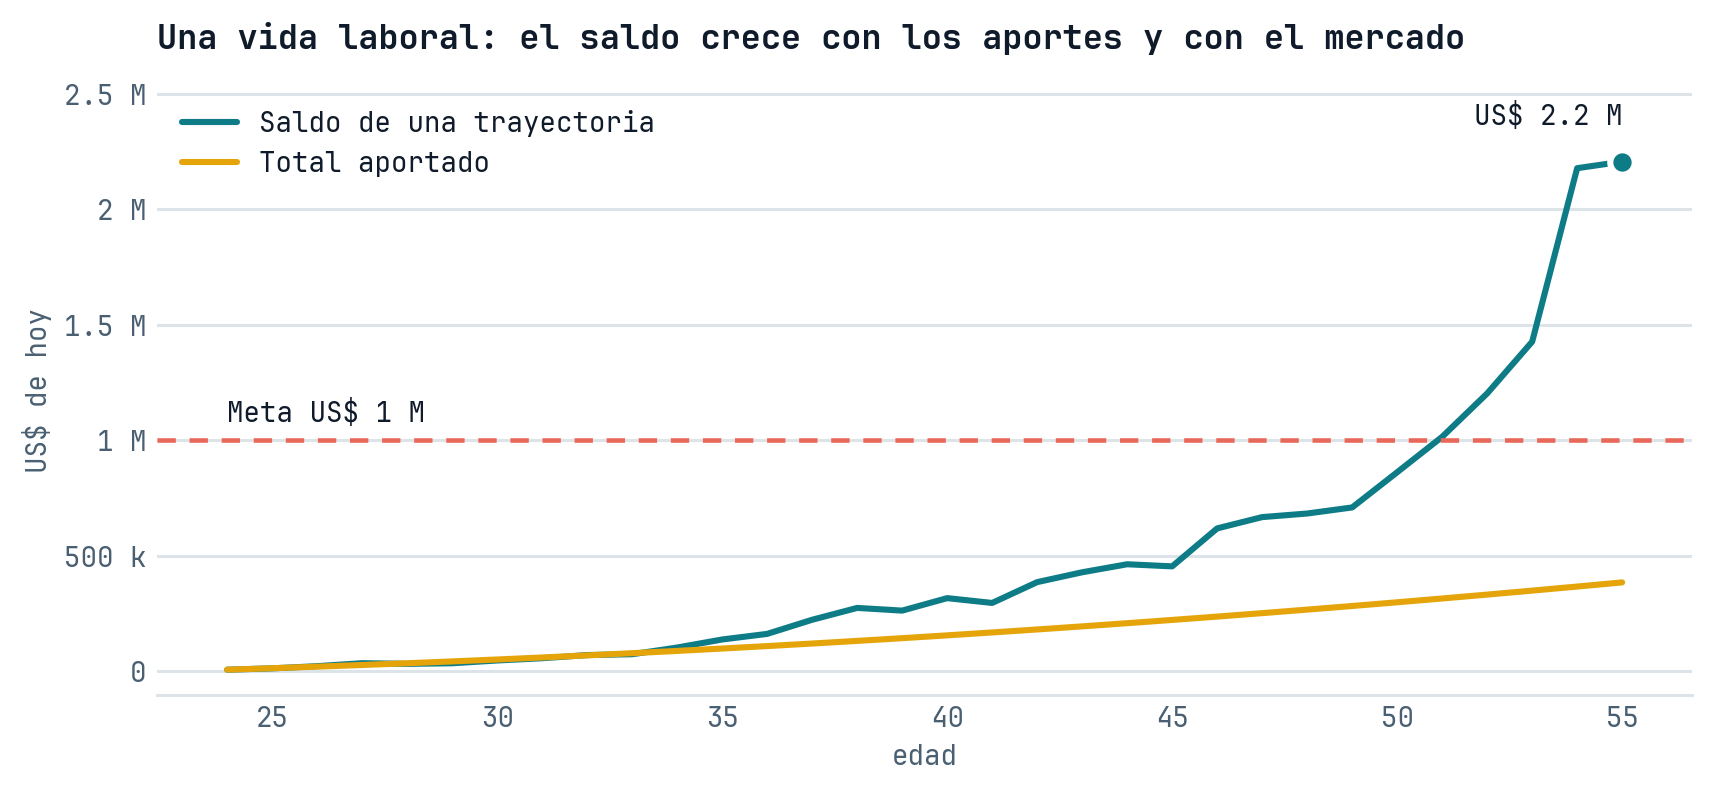

In [7]:
graficas.vida_laboral(edades, vida, aportado, META)

> **Qué se hizo.** Se recorrió una vida laboral completa, de los 23 a los 55 años.
>
> **Cómo.** Un ciclo `for` aplica `actualizar` 32 veces, una por año, con los rendimientos de la primera trayectoria, y guarda el saldo al final de cada año.
>
> **Resultado.** Esta trayectoria termina con USD 2.2 millones: USD 384,000 son aportes y USD 1.8 millones son ganancia del mercado. Es una sola vida posible: con otros rendimientos el resultado sería muy distinto.

## Simular N trayectorias

Miles de vidas laborales posibles.

In [8]:
# Las N vidas laborales a la vez: el ciclo recorre los años y cada paso actualiza todas las trayectorias
saldos = np.empty((N_SIM, HORIZONTE))
saldo = np.zeros(N_SIM)
for t in range(HORIZONTE):
    saldo = actualizar(saldo, R[:, t], aportes[t])
    saldos[:, t] = saldo

# La primera trayectoria coincide con la del paso 03
print("¿La trayectoria 1 coincide con el paso 03?", np.allclose(saldos[0], vida))
pd.DataFrame(
    np.percentile(saldos[:, [9, 19, 31]], [5, 50, 95], axis=0).T,
    index=[f"{e} años" for e in edades[[9, 19, 31]]],
    columns=["P5", "P50", "P95"],
).round(0)

¿La trayectoria 1 coincide con el paso 03? True


,P5,P50,P95
33 años,61572.0,105719.0,181544.0
43 años,166462.0,369240.0,869960.0
55 años,384768.0,1114129.0,3630812.0


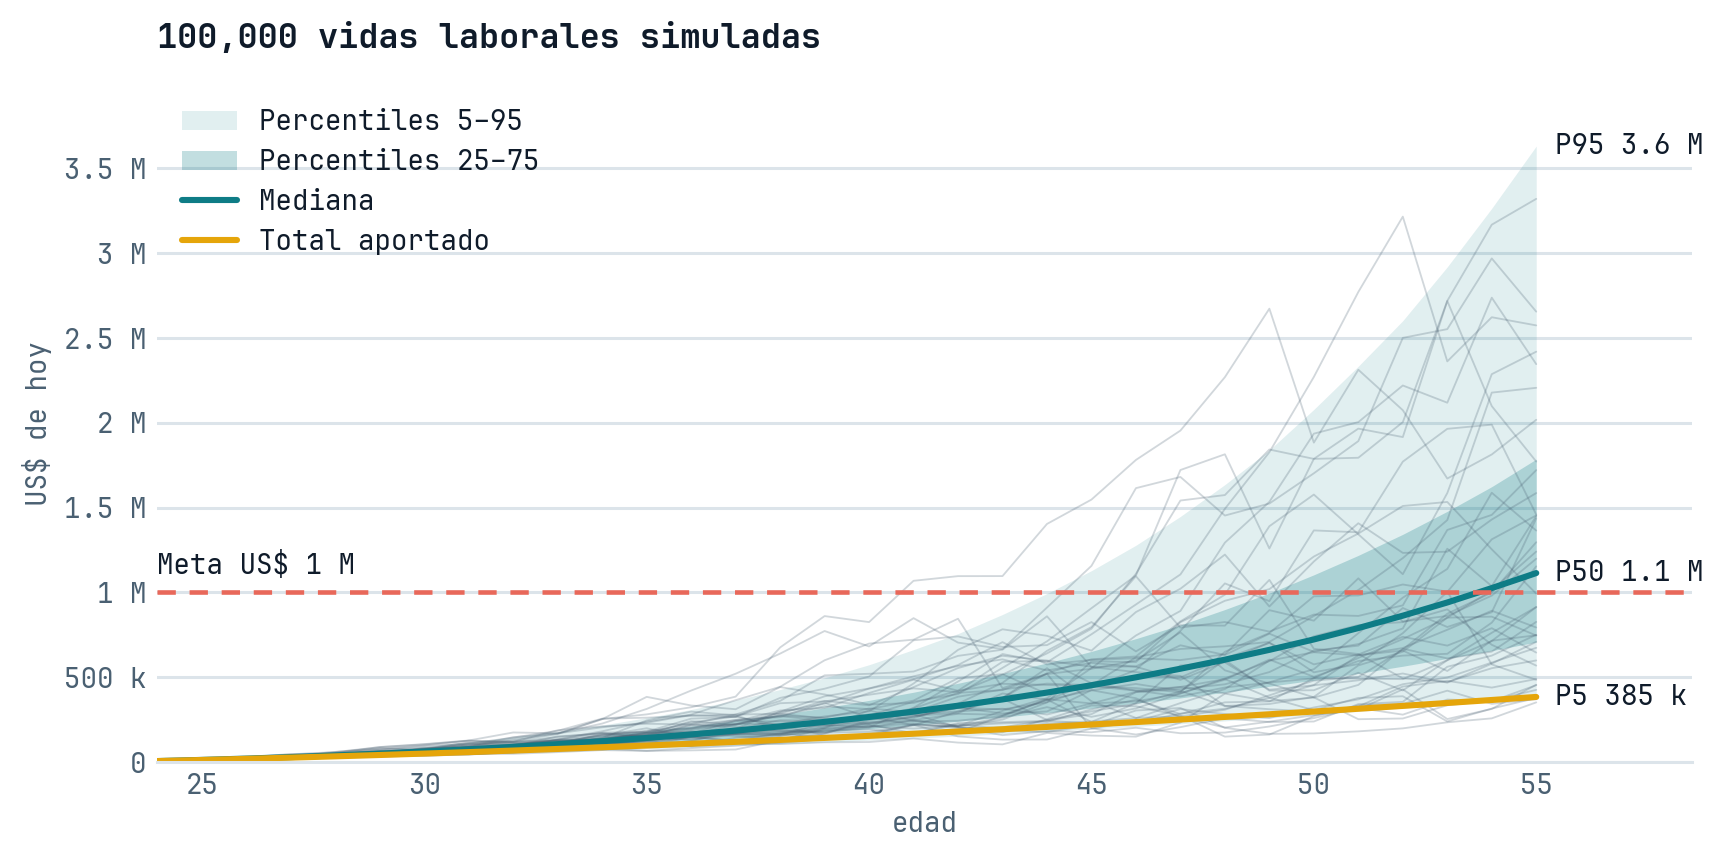

In [9]:
graficas.trayectorias(edades, saldos, META, aportado)

> **Qué se hizo.** Se simularon 100,000 vidas laborales posibles.
>
> **Cómo.** El mismo ciclo del paso 03, pero `actualizar` recibe el vector de saldos de todas las trayectorias y la columna de rendimientos de ese año, así que cada paso actualiza las 100,000 a la vez. Se verificó que la primera trayectoria coincide con la del paso 03.
>
> **Resultado.** Las trayectorias se abren con el tiempo: a los 33 años el rango del 90% central va de USD 62 mil a USD 182 mil; a los 55, de USD 385 mil a USD 3.6 millones.

## Leer el saldo final

Distribución y percentiles 5, 50 y 95.

In [10]:
saldo_final = saldos[:, -1]

pd.Series(
    {
        "percentil 5": np.percentile(saldo_final, 5),
        "percentil 50 (mediana)": np.percentile(saldo_final, 50),
        "percentil 95": np.percentile(saldo_final, 95),
        "media": saldo_final.mean(),
        "total aportado": aportado[-1],
    },
    name="USD a los 55 años",
).round(0).to_frame()

,USD a los 55 años
percentil 5,384768.0
percentil 50 (mediana),1114129.0
percentil 95,3630812.0
media,1449078.0
total aportado,384000.0


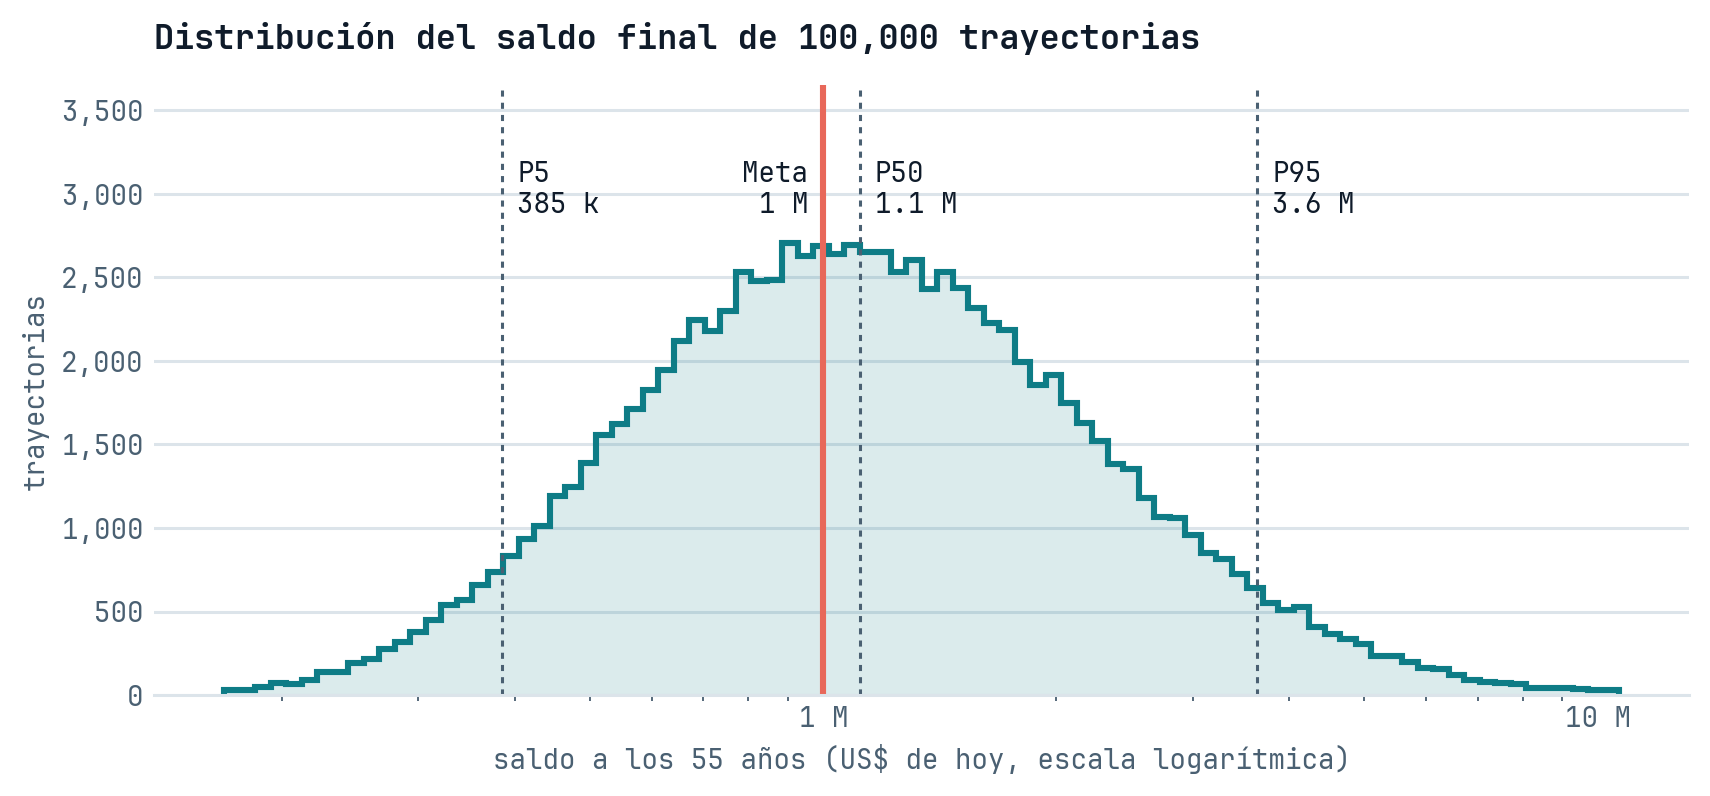

In [11]:
graficas.saldo_final(saldo_final, META)

> **Qué se hizo.** Se analizó la distribución del saldo a los 55 años.
>
> **Cómo.** Se tomó la última columna de `saldos` y se calcularon los percentiles 5, 50 y 95 con `np.percentile`. La gráfica usa un eje logarítmico porque la distribución es muy asimétrica a la derecha.
>
> **Resultado.** La mediana es USD 1.11 millones, apenas por encima de la meta. En el 5% de los peores casos se termina con USD 385 mil o menos, prácticamente lo mismo que se aportó; en el 5% de los mejores, con más de USD 3.6 millones. La media (USD 1.45 millones) supera a la mediana por los escenarios muy buenos.

## Probabilidad de la meta

Proporción que llega, `± 1.96 · √(p(1 − p)/N)`.

In [12]:
llega = saldo_final >= META  # 1 si la trayectoria alcanza la meta, 0 si no
p = llega.mean()
error_estandar = np.sqrt(p * (1 - p) / N_SIM)
margen = 1.96 * error_estandar

print(f"Probabilidad de llegar a US$ {META:,}: {p:.2%} ± {margen:.2%}")
print(f"Intervalo del 95%: {p - margen:.2%} a {p + margen:.2%}")

# El error se reduce como 1/√N: usar las primeras N trayectorias
n = [1_000, 10_000, 100_000]
pd.DataFrame(
    {
        "probabilidad": [llega[:m].mean() for m in n],
        "error estándar": [np.sqrt(llega[:m].mean() * (1 - llega[:m].mean()) / m) for m in n],
    },
    index=pd.Index([f"{m:,}" for m in n], name="N"),
).assign(**{"± 95%": lambda d: 1.96 * d["error estándar"]}).round(4)

Probabilidad de llegar a US$ 1,000,000: 56.23% ± 0.31%
Intervalo del 95%: 55.92% a 56.53%


,probabilidad,error estándar,± 95%
N,,,
"1,000",0.5460,0.0157,0.0309
"10,000",0.5572,0.0050,0.0097
"100,000",0.5622,0.0016,0.0031


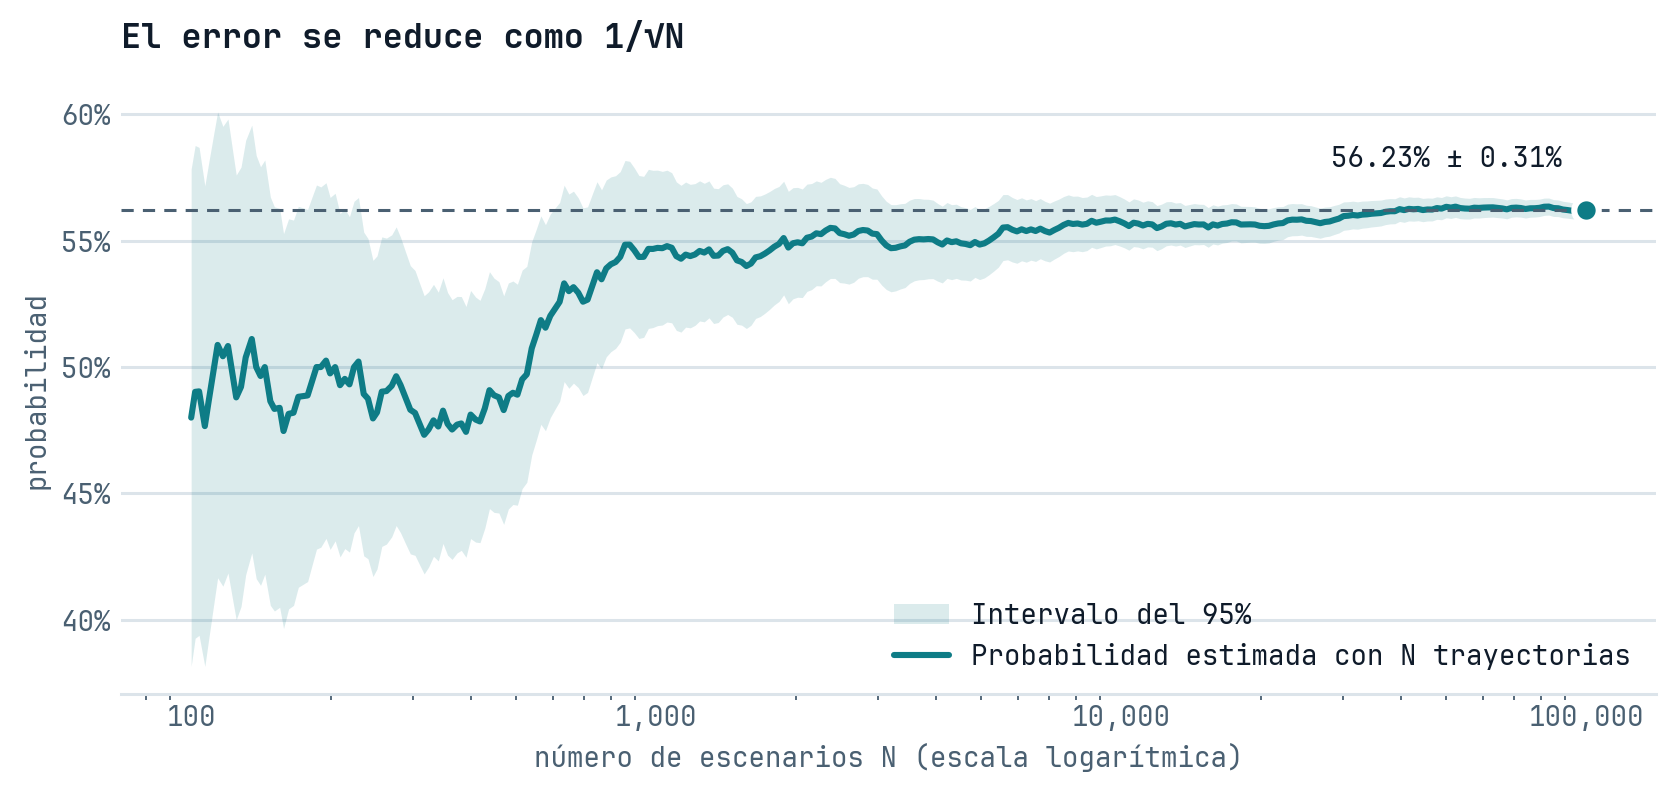

In [13]:
graficas.convergencia(llega, porcentaje=True, etiqueta="Probabilidad estimada con N trayectorias",
                      ylabel="probabilidad", archivo="pen_06_convergencia")

> **Qué se hizo.** Se estimó la probabilidad de alcanzar la meta y su margen de error.
>
> **Cómo.** Cada trayectoria vale 1 si su saldo final llega a USD 1 millón y 0 si no; la probabilidad p es el promedio. El error estándar de una proporción es `√(p(1 − p)/N)` y el intervalo del 95% es p ± 1.96 errores estándar.
>
> **Resultado.** La probabilidad es **56.23% ± 0.31%** (intervalo de 55.92% a 56.53%). El margen pasa de ± 3.09 puntos con 1,000 trayectorias a ± 0.97 con 10,000 y ± 0.31 con 100,000.

<div class="aperture-cierre">

## Conclusiones

</div>

1. **La probabilidad de llegar a USD 1 millón es de 56% (± 0.3%).** Ahorrando de USD 500 a USD 1,500 al mes en VOO entre los 23 y los 55 años, algo más de la mitad de las vidas simuladas alcanza la meta; el 44% restante no.
2. **La meta está justo en el centro de la distribución.** La mediana del saldo final es USD 1.11 millones, apenas por encima del millón. Por eso la probabilidad queda cerca de una moneda al aire: un poco más de aporte o de tiempo la movería bastante.
3. **El mismo esfuerzo puede terminar muy distinto.** Todas las trayectorias aportan exactamente USD 384,000, pero el saldo final va de USD 385 mil (percentil 5) a USD 3.6 millones (percentil 95). La diferencia es solo la secuencia de rendimientos del mercado.
4. **El mercado hace la mayor parte del trabajo.** En la trayectoria mediana el saldo final es casi 3 veces lo aportado. En los peores escenarios, en cambio, se termina con lo mismo que se puso o menos.
5. **Monte Carlo responde preguntas de probabilidad, no solo de promedio.** Con una fórmula se obtiene el saldo esperado; con la simulación se obtiene la distribución completa y la probabilidad de la meta, con un error que se reduce como 1/√N.
6. **El resultado depende de los supuestos.** Se asumieron rendimientos normales, independientes entre años y con μ y σ constantes, aportes que crecen en línea recta y ningún costo. Rendimientos con colas más pesadas o rachas de años malos podrían reducir la probabilidad.